# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/sleep_data.csv', parse_dates=['night', 'bedtime', 'wake_time'])

In [2]:
sns.set_theme(palette='Dark2')

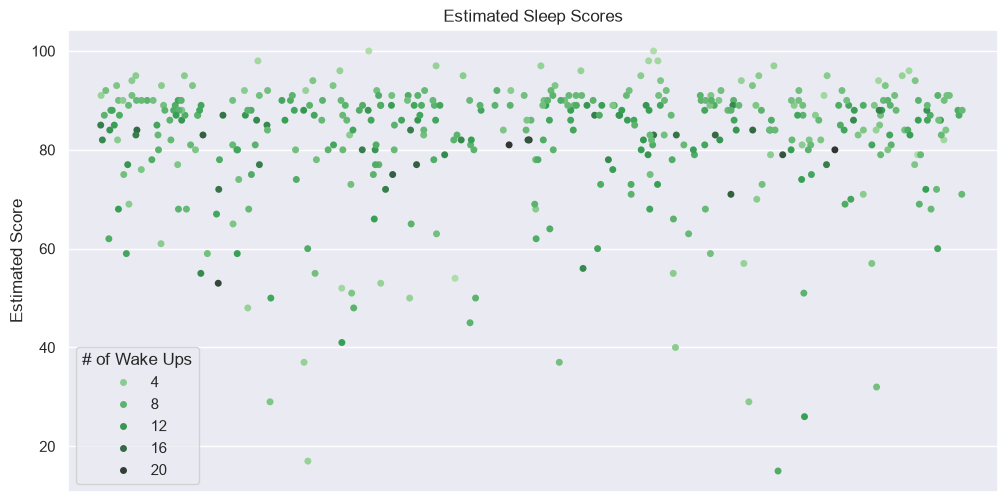

In [3]:
np.random.seed(42)

plt.figure(figsize=(12,6))

sns.stripplot(data=df, y='est_score', hue='wake_ups', jitter=0.47, palette='Greens_d')

plt.title('Estimated Sleep Scores')
plt.ylabel('Estimated Score')
plt.legend(title='# of Wake Ups')

plt.savefig('../visualizations/estimated-sleep-scores.png', bbox_inches='tight')
plt.show()

## Is there a relation between seasons and good sleep?

### Sleep scores by month

In [4]:
sleep_scores_by_month = df.groupby(df['night'].dt.to_period('M')).agg(
    score=('est_score', 'mean'),
    count=('est_score', 'count')
)

sleep_scores_by_month

,score,count
night,,
2025-09,86.083333,12
2025-10,80.296296,27
2025-11,82.928571,28
2025-12,78.193548,31
2026-01,80.300000,30
2026-02,81.821429,28
2026-03,82.275862,29
2026-04,77.433333,30
2026-05,82.870968,31


Even though 2025-09 shows the highest average sleep score, it should be taken with a grain of salt. It is the only month that has less than 20 entries (12 to be exact), and the data could be positively skewed because of it.

In [5]:
sleep_statistics_by_month = sleep_scores_by_month['score'].describe()

mean_sleep_score = sleep_statistics_by_month['mean']

sleep_statistics_by_month

count    15.000000
mean     81.759025
std       2.646353
min      76.933333
25%      80.298148
50%      82.703704
75%      83.084975
max      86.083333
Name: score, dtype: float64

The statistics table helps us better understand the average score per month table above.

- The lowest score is in June 2026, even though temperates are not yet extremely high.
- If we exclude September 2025 (too few entries), the highest average sleep score is in July 2026.
- Winter is more often below the mean sleep score, compared to summer.

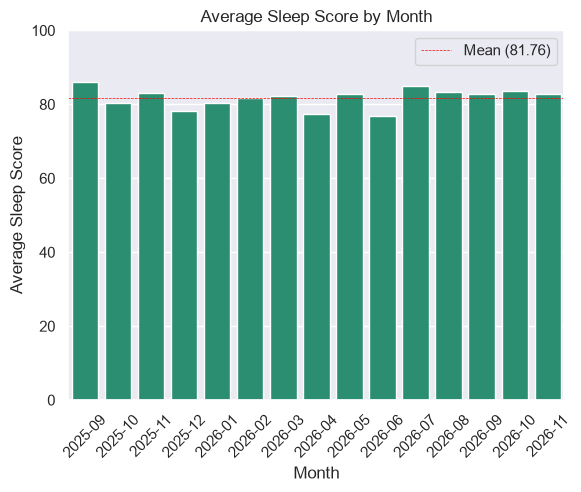

In [6]:
sns.barplot(x=sleep_scores_by_month.index, y=sleep_scores_by_month['score'])

plt.axhline(
    mean_sleep_score,
    color='red',
    linestyle='--',
    linewidth=0.5,
    label=f'Mean ({mean_sleep_score:.2f})'
)

plt.ylim(0, 100)
plt.xticks(rotation=45)

plt.title('Average Sleep Score by Month')
plt.xlabel('Month')
plt.ylabel('Average Sleep Score')
plt.legend()

plt.savefig('../visualizations/average-sleep-score-by-month.png', bbox_inches='tight')
plt.show()

It seems liks summer and autumn have the overall highest sleep scores, with winter and spring being slightly worse. There also seems to be a slight upward general trend, although it's hard to tell with just one year of data.

### Average wake ups by month

In [7]:
average_wake_ups_per_month = df.groupby(df['night'].dt.to_period('M')).agg(
    wake_ups=('wake_ups', 'mean'),
    count=('wake_ups', 'count')
)

average_wake_ups_per_month

,wake_ups,count
night,,
2025-09,9.916667,12
2025-10,10.259259,27
2025-11,7.071429,28
2025-12,9.451613,31
2026-01,6.900000,30
2026-02,7.678571,28
2026-03,7.448276,29
2026-04,8.733333,30
2026-05,8.096774,31


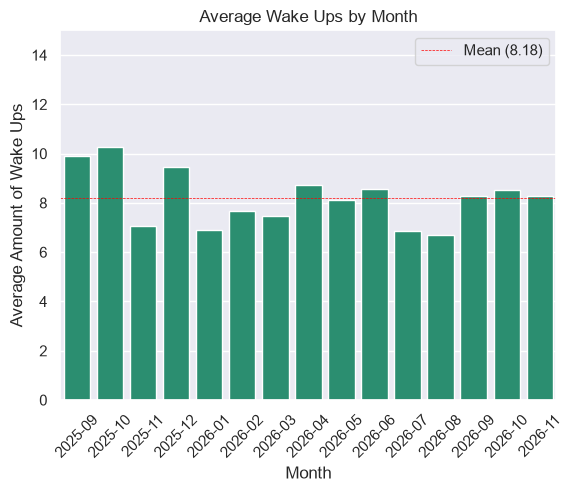

In [8]:
sns.barplot(x=average_wake_ups_per_month.index, y=average_wake_ups_per_month['wake_ups'])

plt.axhline(
    average_wake_ups_per_month['wake_ups'].mean(),
    color='red',
    linestyle='--',
    linewidth=0.5,
    label=f'Mean ({average_wake_ups_per_month['wake_ups'].mean():.2f})'
)

plt.ylim(0, 15)
plt.xticks(rotation=45)

plt.title('Average Wake Ups by Month')
plt.xlabel('Month')
plt.ylabel('Average Amount of Wake Ups')
plt.legend()

plt.savefig('../visualizations/average-wake-ups-by-month.png', bbox_inches='tight')
plt.show()

The average amount of wake ups per month seems to be telling a similar story as the average sleep score, but with more variability. July and August 2026 are the months with least amount of wake ups, but also November 2025 and January 2026 have similar average amounts.

With the amount of wake ups there doesn't seem to be any general trend.

### Bedtime by month

I'm going to do a simple comparison of amount of days per month I go to bed before 00:00 and after 00:00.

In [9]:
df['after_midnight'] = df['bedtime'].dt.date == df['wake_time'].dt.date

df['month'] = df['bedtime'].dt.to_period('M')

counts = (
    pd.crosstab(df['month'], df['after_midnight'])
    .rename(columns={False: 'before_00', True: 'after_00'})
)

counts

after_midnight,before_00,after_00
month,,
2025-09,12,0
2025-10,26,1
2025-11,24,4
2025-12,21,9
2026-01,13,17
2026-02,22,6
2026-03,24,6
2026-04,28,2
2026-05,30,1


December 2025 and January 2026 I've had a significant amount of vacation days, which would answer why I have went to bed later compared to the months around them.

Since July 2026 I haven't been working, and we can see that I started going to bed later, compared to when I was working.

It seems that months where I go to bed after 00:00, I seem to be getting higher sleeping scores overall, with fewer wake ups.

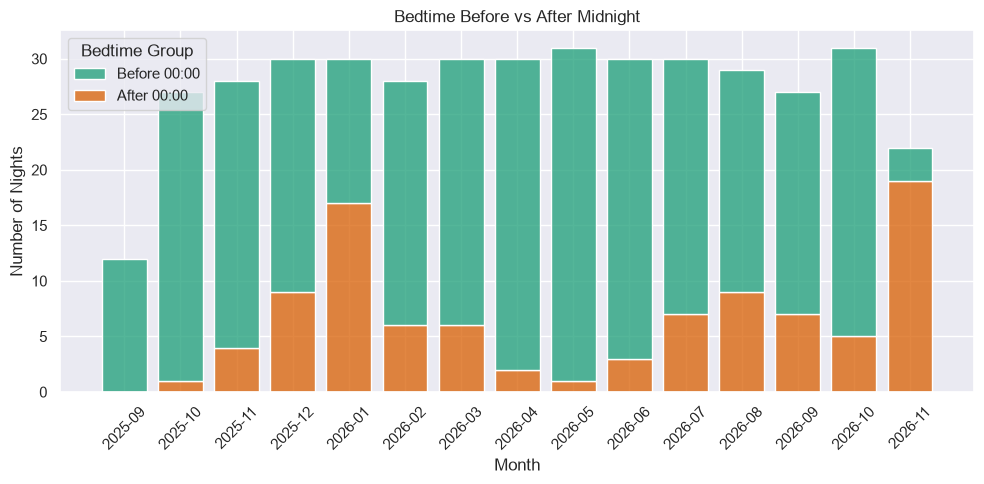

In [10]:
plot_df = df.assign(
    month=df['month'].astype(str),
    bedtime_group=df['after_midnight'].map({False: 'Before 00:00', True: 'After 00:00'})
)

plt.figure(figsize=(10, 5))

g = sns.histplot(
    data=plot_df,
    x='month',
    hue='bedtime_group',
    hue_order=['Before 00:00', 'After 00:00'],
    multiple='stack',
    shrink=0.8
)

plt.xticks(rotation=45)

plt.title('Bedtime Before vs After Midnight')
plt.xlabel('Month')
plt.ylabel('Number of Nights')
sns.move_legend(g, "upper left", title="Bedtime Group")

plt.tight_layout()
plt.savefig('../visualizations/bedtime-before-vs-after-midnight.png', bbox_inches='tight')
plt.show()

## Does going to bed early result in a better sleep?

To answer this, I look at bedtime as a clock time instead of only before/after midnight, and compare it with several measures of sleep:

- **Sleep score** (`est_score`) and its three components. `bedtime_pts` rewards a *consistent* bedtime (it follows `bedtime_dev_min`), not an early one, so the components are worth looking at separately.
- **Duration**: `asleep_min`
- **Interruptions**: `wake_ups`, `awake_min`, and wake ups per hour asleep
- **Sleep stages**: deep and REM sleep, in minutes and as a share of time asleep

In [11]:
bedtime_minutes = df['bedtime'].dt.hour * 60 + df['bedtime'].dt.minute
df['bedtime_rel_min'] = bedtime_minutes.where(bedtime_minutes >= 12 * 60, bedtime_minutes + 24 * 60) - 24 * 60

nap_nights = df[df['bedtime'].dt.hour.between(5, 19)]

nap_nights[['night', 'bedtime', 'wake_time', 'asleep_min', 'est_score']]

,night,bedtime,wake_time,asleep_min,est_score
26,2025-10-18,2025-10-18 15:34:00,2025-10-19 09:38:00,641.3,50
111,2026-01-15,2026-01-15 14:55:00,2026-01-16 07:38:00,468.9,59
189,2026-04-05,2026-04-05 13:12:00,2026-04-06 05:58:00,481.4,60
265,2026-06-20,2026-06-20 13:42:00,2026-06-21 11:43:00,407.3,57
294,2026-07-20,2026-07-20 13:54:00,2026-07-21 06:59:00,528.7,59
343,2026-09-09,2026-09-09 13:54:00,2026-09-10 08:48:00,595.9,50


These 6 nights have a bedtime in the afternoon (13:12–15:34), yet 7 to 11 hours asleep and scores of only 50–60. The bedtime is most likely the start of an afternoon nap that got merged into the night, not when I actually went to bed. If I kept them, they would be the "earliest" bedtimes, all with bad scores, and that would push the answer towards "going to bed early is worse" for the wrong reason. So I leave them out of this question.

In [12]:
bedtime_df = df.drop(nap_nights.index).copy()

bedtime_df['wake_ups_per_hour'] = bedtime_df['wake_ups'] / (bedtime_df['asleep_min'] / 60)

bedtime_df['deep_pct'] = bedtime_df['deep_min'] / bedtime_df['asleep_min'] * 100
bedtime_df['rem_pct'] = bedtime_df['rem_min'] / bedtime_df['asleep_min'] * 100

len(bedtime_df)

409

### Correlation between bedtime and sleep

In [13]:
outcomes = [
    'est_score', 'duration_pts', 'bedtime_pts', 'interruption_pts',
    'asleep_min', 'wake_ups', 'wake_ups_per_hour', 'awake_min',
    'deep_min', 'rem_min', 'deep_pct', 'rem_pct',
]

bedtime_correlations = (
    bedtime_df[outcomes].rank()
    .corrwith(bedtime_df['bedtime_rel_min'].rank())
    .round(2)
    .rename('spearman_r')
)

bedtime_correlations

est_score           -0.19
duration_pts        -0.30
bedtime_pts         -0.26
interruption_pts     0.22
asleep_min          -0.34
wake_ups            -0.24
wake_ups_per_hour   -0.13
awake_min           -0.20
deep_min            -0.11
rem_min             -0.20
deep_pct             0.01
rem_pct             -0.01
Name: spearman_r, dtype: float64

- The strongest relation is with duration: the later I go to bed, the less I sleep (r = −0.34).
- The sleep score drops slightly with later bedtimes (r = −0.19). Part of this comes from `bedtime_pts`: late bedtimes are unusual for me, so they are also the inconsistent ones.
- Later bedtimes come with *fewer* wake ups (r = −0.24), but mostly because a shorter night has less time to wake up in. Per hour asleep the relation is weak (r = −0.13).
- The *share* of deep and REM sleep doesn't depend on bedtime at all (r ≈ 0). Later bedtimes only mean fewer minutes of REM because the night is shorter.

All of these are weak to moderate correlations, so bedtime explains only part of how a night goes.

### Sleep by bedtime group

In [14]:
bedtime_bins = [-np.inf, -90, -30, 30, np.inf]
bedtime_labels = ['Before 22:30', '22:30–23:30', '23:30–00:30', 'After 00:30']

bedtime_df['bedtime_group'] = pd.cut(
    bedtime_df['bedtime_rel_min'],
    bins=bedtime_bins,
    labels=bedtime_labels,
    right=False,
)

sleep_by_bedtime = bedtime_df.groupby('bedtime_group', observed=True).agg(
    nights=('est_score', 'count'),
    score_mean=('est_score', 'mean'),
    score_median=('est_score', 'median'),
    asleep_h=('asleep_h', 'mean'),
    wake_ups=('wake_ups', 'mean'),
    wake_ups_per_hour=('wake_ups_per_hour', 'mean'),
    deep_pct=('deep_pct', 'mean'),
    rem_pct=('rem_pct', 'mean'),
)

sleep_by_bedtime.round(2)

,nights,score_mean,score_median,asleep_h,wake_ups,wake_ups_per_hour,deep_pct,rem_pct
bedtime_group,,,,,,,,
Before 22:30,95,82.63,86.0,8.23,9.57,1.18,11.35,23.27
22:30–23:30,158,85.89,88.0,7.91,7.94,1.01,12.06,24.10
23:30–00:30,98,83.19,85.5,7.65,7.48,0.99,11.33,24.02
After 00:30,58,67.79,75.0,7.17,7.24,1.02,12.13,23.04


- The best nights have a bedtime between 22:30 and 23:30 (mean 85.9, median 88), not the earliest ones.
- Going to bed before 22:30 gives the most sleep (8.2 h), but also the most wake ups, both in total (9.6) and per hour asleep (1.18).
- After 00:30 is clearly worse: the mean score drops to 67.8 and time asleep to 7.2 h. This is also the smallest group (58 nights).
- The share of deep (11–12%) and REM (23–24%) sleep is about the same in every group.

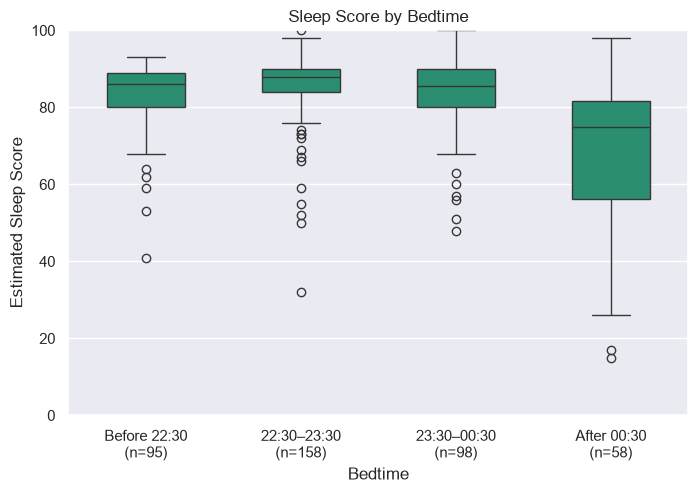

In [15]:
group_sizes = sleep_by_bedtime['nights']

plt.figure(figsize=(8, 5))

ax = sns.boxplot(
    data=bedtime_df,
    x='bedtime_group',
    y='est_score',
    color=sns.color_palette('Dark2')[0],
    width=0.5,
)

ax.set_xticks(range(len(bedtime_labels)))
ax.set_xticklabels([f'{label}\n(n={group_sizes[label]})' for label in bedtime_labels])

plt.ylim(0, 100)

plt.title('Sleep Score by Bedtime')
plt.xlabel('Bedtime')
plt.ylabel('Estimated Sleep Score')

plt.savefig('../visualizations/sleep-score-by-bedtime.png', bbox_inches='tight')
plt.show()

The spread is also much wider after 00:30. Some late nights still score in the 90s, but most of the very low scores are in this group.

### Which part of the score is lost

In [16]:
max_points = pd.Series({'duration_pts': 50, 'bedtime_pts': 30, 'interruption_pts': 20})

points_lost = (
    bedtime_df.groupby('bedtime_group', observed=True)[max_points.index]
    .mean()
    .rsub(max_points)
    .rename(columns={
        'duration_pts': 'Duration',
        'bedtime_pts': 'Bedtime consistency',
        'interruption_pts': 'Interruptions',
    })
)

points_lost.round(1)

,Duration,Bedtime consistency,Interruptions
bedtime_group,,,
Before 22:30,1.4,3.6,12.4
22:30–23:30,2.3,1.5,10.3
23:30–00:30,3.8,3.1,10.0
After 00:30,9.3,13.0,10.0


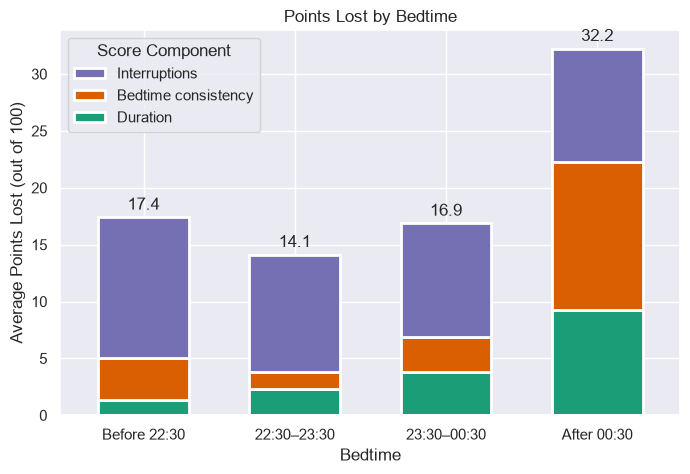

In [17]:
ax = points_lost.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=sns.color_palette('Dark2')[:3],
    edgecolor='white',
    linewidth=2,
    width=0.6,
)

ax.bar_label(
    ax.containers[-1],
    labels=[f'{total:.1f}' for total in points_lost.sum(axis=1)],
    padding=3,
)

plt.xticks(rotation=0)

plt.title('Points Lost by Bedtime')
plt.xlabel('Bedtime')
plt.ylabel('Average Points Lost (out of 100)')

handles, labels = ax.get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1], title='Score Component')

plt.savefig('../visualizations/points-lost-by-bedtime.png', bbox_inches='tight')
plt.show()

- After 00:30, the extra lost points come from duration (9.3 vs 1.4–3.8 in the other groups) and bedtime consistency (13.0 vs 1.5–3.6). Interruptions cost about the same as in the other groups.
- Before 22:30, interruptions cost the most (12.4 points), which matches the higher number of wake ups per hour.
- 22:30–23:30 loses the fewest points overall (14.1).

### Time asleep by bedtime

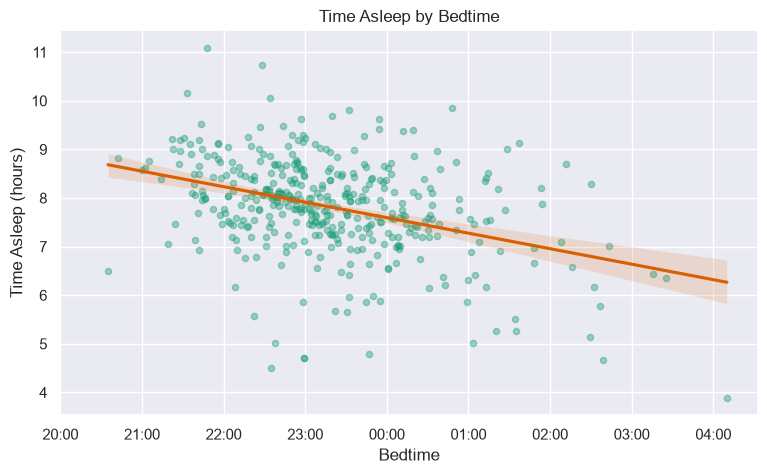

In [18]:
plt.figure(figsize=(9, 5))

ax = sns.regplot(
    data=bedtime_df,
    x='bedtime_rel_min',
    y='asleep_h',
    scatter_kws={'alpha': 0.4, 's': 20},
    line_kws={'color': sns.color_palette('Dark2')[1]},
)

tick_positions = range(-240, 241, 60)
ax.set_xticks(tick_positions)
ax.set_xticklabels([f'{(24 + minutes // 60) % 24:02d}:00' for minutes in tick_positions])

plt.title('Time Asleep by Bedtime')
plt.xlabel('Bedtime')
plt.ylabel('Time Asleep (hours)')

plt.savefig('../visualizations/time-asleep-by-bedtime.png', bbox_inches='tight')
plt.show()

The trend line goes from about 8.7 hours asleep for a bedtime around 20:30 down to about 6.3 hours around 04:00. On average, getting up later after a late night doesn't make up for the lost sleep.

### Conclusion

Going to bed early does not by itself give a better sleep, but going to bed late does give a worse one.

- The best scores come with a bedtime between 22:30 and 23:30. Going to bed earlier than that gives longer nights, but with more wake ups per hour.
- A bedtime after 00:30 lowers the score sharply (mean 67.8 vs 82.6–85.9 in the other groups), mostly because I sleep less and because those bedtimes are irregular for me.
- Bedtime doesn't change how much of the night is deep or REM sleep.

My hypothesis that going to bed later results in better sleep is not supported. The month-level comparison in the previous section (months with more late bedtimes seeming to score higher) doesn't hold when looking at individual nights.

These are correlations, not causes. Late nights can have their own reasons (going out, stress, vacation) that also affect how I sleep.